# Comparing AR and NoAR Flowmatching for forecasting

This notebook compares autoregressive (AR) and non-autoregressive (NoAR) approaches to forecasting dynamical systems.

In [1]:
import jax
import jax.numpy as jnp
import jax.random as jrandom
import matplotlib.pyplot as plt
import flax.nnx as nnx

from config import ModelConfig
from systems import create_system
from models import ARFlow, NoARFlow
from training import prepare_data, ARTrainer, NoARTrainer
from visualization import plot_loss, plot_trajectories

%matplotlib inline

## Configuration

In [2]:
# Set random seed
key = jrandom.PRNGKey(0)

# Set up configuration
config = ModelConfig(
    system='lorenz',
    num_timepoints=200,
    history_size=50,
    prediction_size=100,
    stochastic=False,
    t0=0,
    t1=2.0,
    n_train_test_samples=1024,
    batch_size=64
)

# Create system
system = create_system(config.system, config.stochastic)

## Data Preparation

In [3]:
# Prepare training and test data
(train_loader, train_trajectories), (test_loader, test_trajectories) = prepare_data(system, config, key)

## Model Setup

In [4]:
# Initialize models
key, key_ar, key_noar = jrandom.split(key, 3)

# AR Model
ar_model = ARFlow(
    dim_x=system.data_dim,
    dim_c=config.covariates_dim,
    dim_h=config.hidden_dim,
    dim_t=config.time_dim,
    dim_hidden=config.hidden_dim,
    hidden_blocks=config.hidden_blocks,
    n_rnn_layers=config.n_rnn_layers,
    rnn_hidden=config.rnn_hidden,
    rngs=nnx.Rngs(key_ar)
)

# NoAR Model
noar_model = NoARFlow(
    dim_x=system.data_dim,
    dim_c=config.covariates_dim,
    dim_h=config.hidden_dim,
    dim_t=config.time_dim,
    dim_hidden=config.hidden_dim,
    hidden_blocks=config.hidden_blocks,
    n_rnn_layers=config.n_rnn_layers,
    rngs=nnx.Rngs(key_noar)
)

## Training

In [5]:
# Train NoAR model
ar_trainer = ARTrainer(ar_model, learning_rate=config.learning_rate)
noar_trainer = NoARTrainer(noar_model, learning_rate=config.learning_rate)

# Train models
ar_losses = ar_trainer.train(train_loader, test_loader, num_epochs=100)
noar_losses = noar_trainer.train(train_loader, test_loader, num_epochs=100)

100%|██████████| 100/100 [05:18<00:00,  3.19s/it]


## Visualization

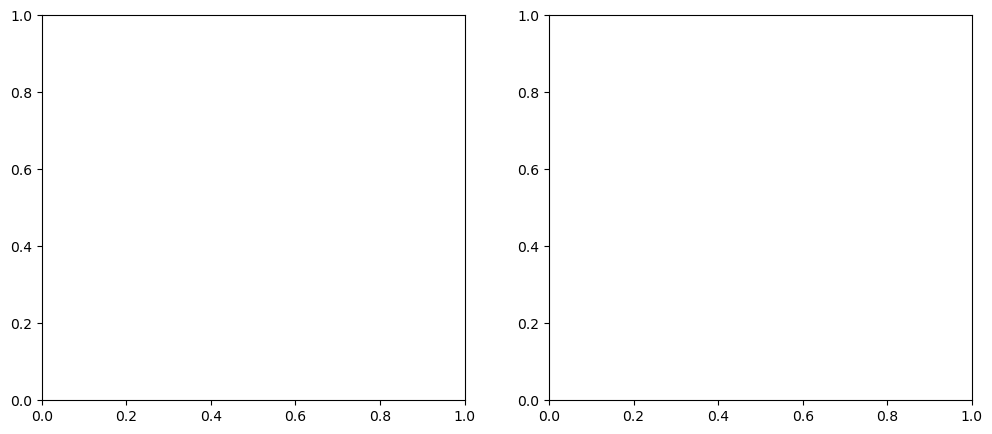

In [10]:
# Plot training losses
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plot_loss(ar_losses[0], ar_losses[1], 
         title='AR Model Training',
         save_path='figures/ar_loss.pdf')

plt.subplot(1, 2, 2)
plot_loss(noar_losses[0], noar_losses[1],
         title='NoAR Model Training',
         save_path='figures/noar_loss.pdf')

In [11]:
import diffrax as dfx 
from seq_priors import generate_brownian_timeseries


def sample_flow(model, key, history, covariates, n_steps_flow, n_steps_pred, n_samples):

    def predict_noar(key, history, covariates, n_steps_flow, n_steps_pred):
        def vf(t, x, args):
            history, covariates = args
            return model(x, history, covariates, t)
            
        term = dfx.ODETerm(vf)
        solver = dfx.Euler()
        dt = 1/n_steps_flow
        x0 = generate_brownian_timeseries(key, history.shape[-1], n_steps_pred).T
        predictions = dfx.diffeqsolve(term, solver, 0., 1., dt, x0, args=(history, covariates), saveat=dfx.SaveAt(t1=True)).ys
        return predictions
    
    def predict_ar(key, history, covariates, n_steps_flow, n_steps_pred):
        def vf(t, x, args):
            history, covariates = args
            return model(x, history, covariates, jnp.array([t]))
            
        term = dfx.ODETerm(vf)
        solver = dfx.Euler()
        dt = 1/n_steps_flow
        predictions = []
        current_history = history
        context_length = history.shape[0]
        for _ in range(n_steps_pred):
            context = current_history[-context_length:]
            x0 = jrandom.normal(key, shape=context.shape[-1])
            x_next = dfx.diffeqsolve(
                term, solver, 0., 1., dt, x0, 
                args=(context, covariates), 
                saveat=dfx.SaveAt(t1=True)
            ).ys
            predictions.append(x_next)
            current_history = jnp.concatenate([current_history, x_next], axis=0)
            
        predictions = jnp.vstack(predictions)
        return predictions

    key_samples = jrandom.split(key, n_samples)

    if isinstance(model, NoARFlow):
        predict = predict_noar
    else:
        predict = predict_ar
    
    # First vmap over batch, then over samples
    vmapped_predict = jax.vmap(predict, in_axes=(None, 0, 0, None, None))  # vmap over batch
    vmapped_predict = jax.vmap(vmapped_predict, in_axes=(0, None, None, None, None))  # vmap over samples
    
    pred_samples = vmapped_predict(key_samples, history, covariates, n_steps_flow, n_steps_pred)
    return pred_samples

In [14]:
# Generate predictions
def sample_trajectories(model, key, num_samples=50):
    # Get first batch from test loader
    history, covariates, true_future, true_exp = next(iter(test_loader))
    true_fe = jnp.concatenate([true_future, true_exp], axis=1)
    predictions = sample_flow(model, key, history, covariates, n_steps_flow=10, n_steps_pred=config.prediction_size+config.extrapolation_size, n_samples=num_samples)
    return jnp.stack(predictions), history, true_fe

# Generate and plot predictions
key, key_ar, key_noar = jrandom.split(key, 3)

ar_predictions, ar_history, ar_true = sample_trajectories(ar_model, key)
noar_predictions, noar_history, noar_true = sample_trajectories(noar_model, key)
noar_predictions = jnp.squeeze(noar_predictions, axis=2)


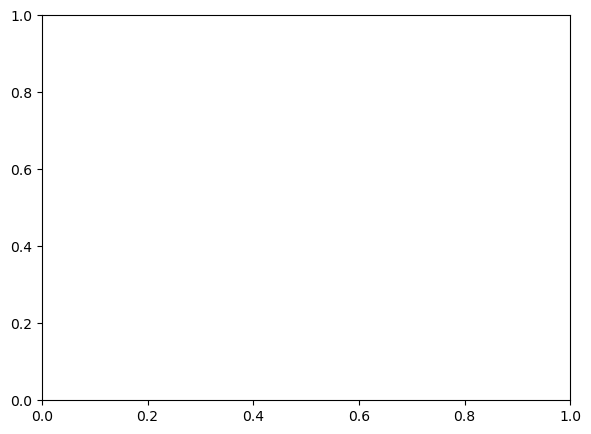

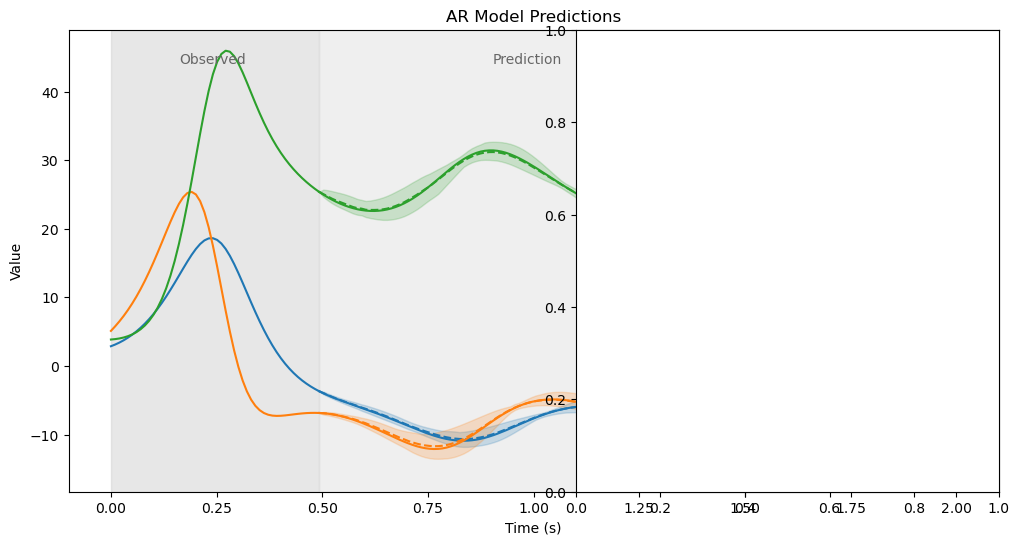

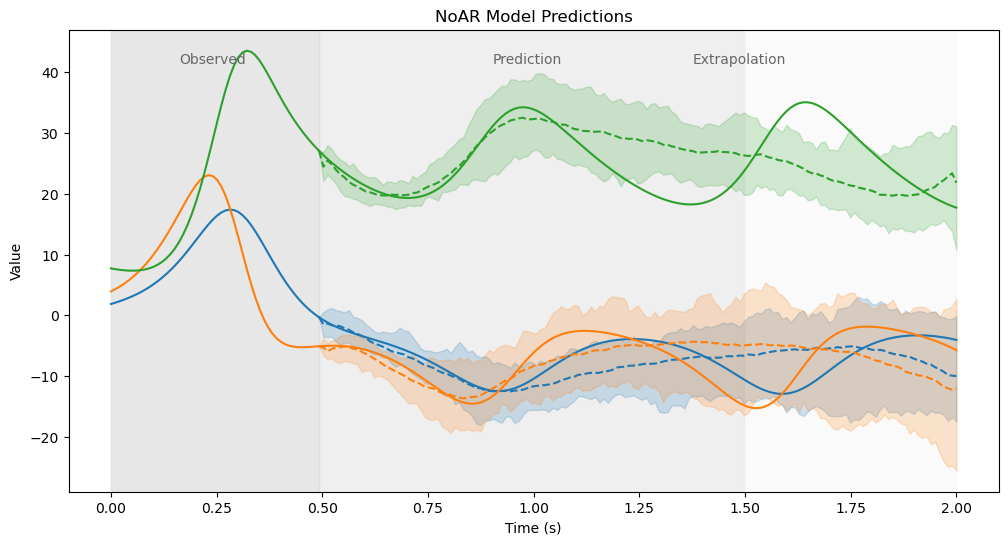

In [15]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
idx = 1
plot_trajectories(config.ts, ar_history[idx], ar_predictions[:,idx], ar_true[idx], 
    config.extrapolation_size,
    title='AR Model Predictions',
    save_path=f'figures/{config.system}/ar_predictions.pdf'
)

plt.subplot(1, 2, 2)
plot_trajectories(
    config.ts, noar_history[idx], noar_predictions[:,idx], noar_true[idx],
    config.extrapolation_size,
    title='NoAR Model Predictions',
    save_path=f'figures/{config.system}/noar_predictions.pdf'
)